# Phase 4 — How short can promises be, and what does it cost?

Every promise policy sits somewhere on a trade-off between **how long customers are told to wait** and
**how often that promise is broken**. Phase 2 priced a broken promise: about 2 stars per late order, while each
extra week of slack is worth about 0.16 stars. Phase 3 produced calibrated delivery-time distributions per order.
This notebook combines them.

**Policies compared** (all evaluated on what actually happened, Feb–Aug 2018; orders never delivered count as late)

| Policy | Promise for each order |
|---|---|
| Olist, shifted | Olist's own promise + *k* days for everyone (the only lever Olist has today) |
| Model, same quantile | the model's *q*-th percentile, so every order carries the same risk of being late |
| Model, cost-aware | the day *d* minimising *d + r · P(late by d)*, which gives tight-distribution orders tight promises and stops padding very uncertain ones |

**Honest set-up.** Choices that would have to be made in advance (which quantile to deploy) are tuned on the
calibration month (January 2018) and only then evaluated on February–August.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT / "analysis"))
import causal as C  # noqa: E402
import policy as Y  # noqa: E402

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
DB = str(ROOT / "warehouse" / "olist.duckdb")
FIG = ROOT / "docs" / "figures"

BLUE, ORANGE, AQUA, INK, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})

## 1. Inputs

In [2]:
preds = pd.read_parquet(ROOT / "warehouse" / "phase3_predictions.parquet")
calib = preds[preds.split == "calib"].reset_index(drop=True)
test = preds[preds.split == "test"].reset_index(drop=True)
cdf_calib, cdf_test = Y.cdf_grid(calib), Y.cdf_grid(test)

# Phase 2 dose-response: adjusted review change by arrival vs promise (stars, and 1-star probability).
orders = C.load_orders(DB)
stars = Y.bucket_effects(C.dose_response(orders, "review_score"))
one_star = Y.bucket_effects(C.dose_response(orders, "one_star"))
pd.DataFrame({"stars": stars, "1-star probability": one_star})

,stars,1-star probability
1. 15+ days early,0.326,-0.035
2. 8-14 days early,0.174,-0.015
3. 1-7 days early,0.000,0.000
4. on the day,-0.162,0.014
5. 1-3 days late,-0.848,0.172
6. 4-7 days late,-2.018,0.504
7. 8-14 days late,-2.422,0.620
8. 15+ days late,-2.338,0.598


Two assumptions carry over from Phase 2. First, the review reacts to **arrival relative to the promise**, not to
the promise length itself. Second, the review penalty for each lateness bucket is the same under a new policy as
it was under Olist's. Both are reasonable for a first pass and both are exactly what Phase 5's experiment would test.

## 2. The frontier

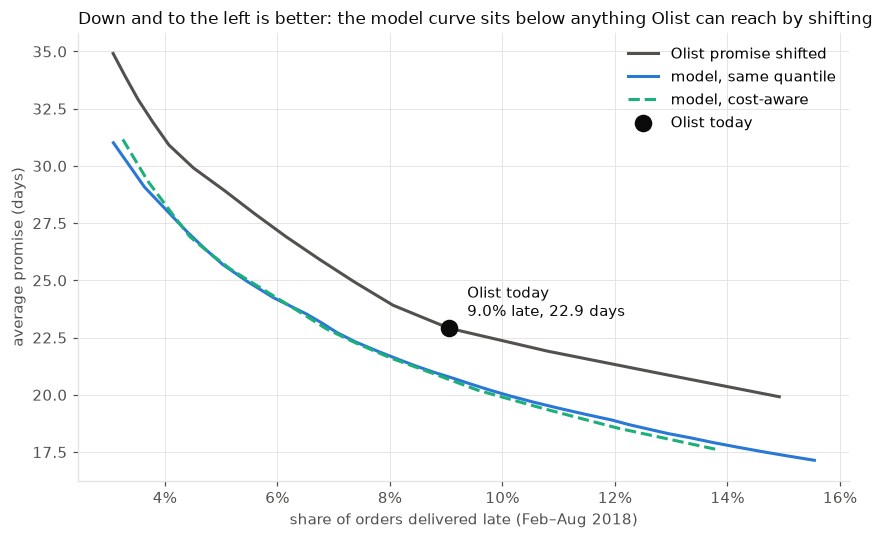

In [3]:
front = Y.frontier(test, cdf_test, stars)
olist = Y.evaluate(test.promised_days.to_numpy(float), test, stars)

fig, ax = plt.subplots(figsize=(8, 5))
styles = {
    "Olist promise shifted": dict(color=INK2, ls="-"),
    "model, same quantile": dict(color=BLUE, ls="-"),
    "model, cost-aware": dict(color=AQUA, ls="--"),
}
for name, st in styles.items():
    f = front[(front.policy == name) & (front.late_rate.between(0.03, 0.16))].sort_values("late_rate")
    ax.plot(f.late_rate, f.avg_promise_days, lw=2, label=name, **st)
ax.scatter([olist["late_rate"]], [olist["avg_promise_days"]], s=110, color=INK, zorder=5, label="Olist today")
ax.annotate(f"Olist today\n{olist['late_rate']:.1%} late, {olist['avg_promise_days']:.1f} days",
            (olist["late_rate"], olist["avg_promise_days"]), xytext=(12, 8), textcoords="offset points", color=INK)
ax.set_xlabel("share of orders delivered late (Feb–Aug 2018)")
ax.set_ylabel("average promise (days)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Down and to the left is better: the model curve sits below anything Olist can reach by shifting",
             loc="left", fontsize=11)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "04_frontier.png", bbox_inches="tight")

Shifting Olist's promises only slides along the grey line: shorter promises cost a lot of extra lateness
(3 days shorter takes the late rate from 9% to 15%). The model's curve is lower everywhere in the useful range.
The cost-aware rule is practically identical to the simpler same-quantile rule, so the simpler rule wins.

## 3. Reading the frontier: three options

* **A. Fewer late orders, same average promise.** Read off the test frontier at Olist's 22.9 days.
* **B. Shorter promises, same late rate.** Read off the test frontier at Olist's 9.0%.
* **C. Deployable.** The quantile chosen *in January* to match Olist's January late rate, then run unchanged
  through Feb–Aug. This is what Olist would actually have got.

In [4]:
def at_promise(days):
    f = front[front.policy == "model, same quantile"].sort_values("avg_promise_days")
    return float(np.interp(days, f.avg_promise_days, f.param))

def at_late(rate):
    f = front[front.policy == "model, same quantile"].sort_values("late_rate")
    return float(np.interp(rate, f.late_rate, f.param))

olist_calib = Y.evaluate(calib.promised_days.to_numpy(float), calib)
q_deploy = Y.tune(calib, cdf_calib, "uniform_quantile", "late_rate", olist_calib["late_rate"])

options = {
    "Olist today": test.promised_days.to_numpy(float),
    "A. fewer late, same avg promise": Y.uniform_quantile(cdf_test, at_promise(olist["avg_promise_days"])),
    "B. shorter promises, same late rate": Y.uniform_quantile(cdf_test, at_late(olist["late_rate"])),
    f"C. deployable (P{q_deploy * 100:g}, chosen in Jan)": Y.uniform_quantile(cdf_test, q_deploy),
}
rows = []
for name, prom in options.items():
    late_days = Y.days_late(prom, test)
    rows.append({
        "option": name,
        "late rate": (late_days > 0).mean(),
        "avg promise (days)": prom.mean(),
        "review effect (stars)": Y.expected_review(late_days, stars).mean(),
        "1-star rate effect": Y.expected_review(late_days, one_star).mean(),
        "promise shorter than Olist's": (prom < test.promised_days).mean(),
        "promise longer than Olist's": (prom > test.promised_days).mean(),
    })
opt = pd.DataFrame(rows).set_index("option")
base = opt.loc["Olist today"]
per10k = pd.DataFrame({
    "late orders avoided": (base["late rate"] - opt["late rate"]) * 10_000,
    "days shorter on average": base["avg promise (days)"] - opt["avg promise (days)"],
    "avg review change (stars)": opt["review effect (stars)"] - base["review effect (stars)"],
    "1-star reviews avoided": (base["1-star rate effect"] - opt["1-star rate effect"]) * 10_000,
})
print(f"deployable quantile chosen on January: P{q_deploy * 100:g}")
opt

deployable quantile chosen on January: P92.5


,late rate,avg promise (days),review effect (stars),1-star rate effect,promise shorter than Olist's,promise longer than Olist's
option,,,,,,
Olist today,0.090,22.912,-0.009,0.026,0.000,0.000
"A. fewer late, same avg promise",0.069,22.911,0.037,0.015,0.466,0.467
"B. shorter promises, same late rate",0.091,20.784,-0.032,0.027,0.600,0.334
"C. deployable (P92.5, chosen in Jan)",0.065,23.527,0.053,0.012,0.431,0.502


In [5]:
per10k.round(2).rename_axis("per 10,000 orders")

,late orders avoided,days shorter on average,avg review change (stars),1-star reviews avoided
"per 10,000 orders",,,,
Olist today,0.000,0.000,0.000,0.000
"A. fewer late, same avg promise",210.050,0.000,0.050,112.140
"B. shorter promises, same late rate",-0.220,2.130,-0.020,-8.260
"C. deployable (P92.5, chosen in Jan)",252.850,-0.620,0.060,140.660


## 4. Where does the improvement come from?

The model does not shorten every promise. It **moves slack from where it is wasted to where it is missing**.
Per destination state, deployable option C vs Olist:

In [6]:
prom_c = options[[k for k in options if k.startswith("C.")][0]]
st = test.assign(
    model_promise=prom_c,
    olist_late=Y.days_late(test.promised_days.to_numpy(float), test) > 0,
    model_late=Y.days_late(prom_c, test) > 0,
).groupby("customer_state").agg(
    orders=("order_id", "size"), olist_promise=("promised_days", "mean"), model_promise=("model_promise", "mean"),
    olist_late=("olist_late", "mean"), model_late=("model_late", "mean"),
)
st = st[st.orders >= 300].sort_values("orders", ascending=False)
st

,orders,olist_promise,model_promise,olist_late,model_late
customer_state,,,,,
SP,20442,18.048,16.337,0.059,0.058
RJ,5609,28.394,33.358,0.160,0.083
MG,5243,23.865,23.009,0.073,0.062
RS,2373,28.422,31.142,0.078,0.046
PR,2341,23.629,23.672,0.058,0.044
SC,1571,25.402,29.150,0.092,0.037
BA,1527,28.499,33.912,0.170,0.088
DF,1067,23.297,24.027,0.082,0.056
ES,903,24.718,28.553,0.152,0.085


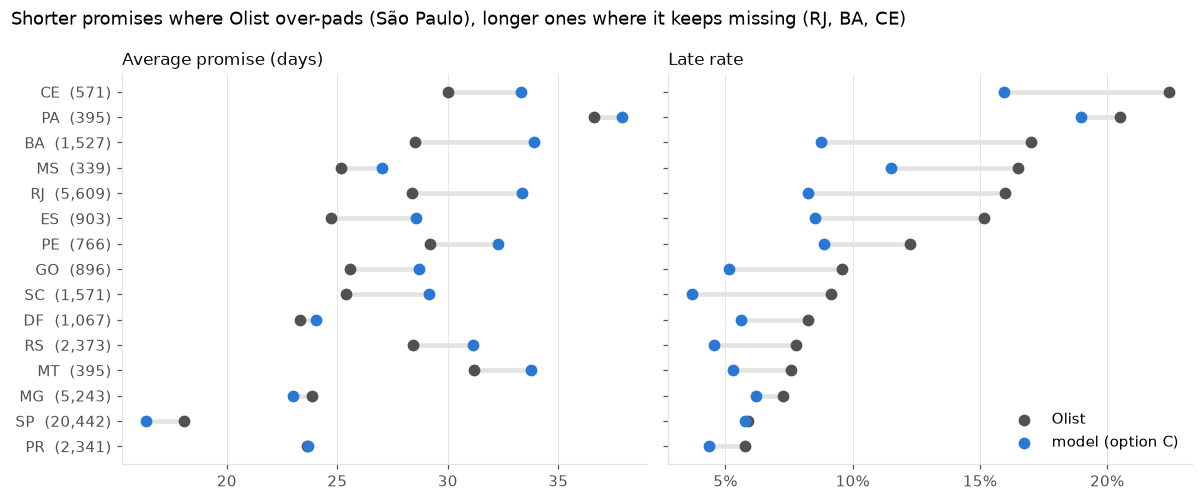

In [7]:
s = st.sort_values("olist_late")
y = np.arange(len(s))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, (a, b, title, fmt) in zip(axes, [
    ("olist_promise", "model_promise", "Average promise (days)", lambda v: f"{v:.0f}"),
    ("olist_late", "model_late", "Late rate", lambda v: f"{v:.0%}"),
], strict=True):
    ax.hlines(y, s[[a, b]].min(axis=1), s[[a, b]].max(axis=1), color=GRID, lw=3, zorder=1)
    ax.scatter(s[a], y, color=INK2, s=45, zorder=3, label="Olist")
    ax.scatter(s[b], y, color=BLUE, s=45, zorder=3, label="model (option C)")
    ax.set_title(title, loc="left", fontsize=11)
    ax.xaxis.set_major_formatter(lambda v, _, f=fmt: f(v))
    ax.grid(axis="y", visible=False)
axes[1].xaxis.set_major_locator(plt.MultipleLocator(0.05))
axes[0].set_yticks(y, [f"{i}  ({n:,})" for i, n in zip(s.index, s.orders, strict=True)])
axes[1].legend(loc="lower right")
fig.suptitle("Shorter promises where Olist over-pads (São Paulo), longer ones where it keeps missing (RJ, BA, CE)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "04_by_state.png", bbox_inches="tight")

Olist's promises are too generous for São Paulo, which is 44% of orders and usually same-state, and too
tight for Rio de Janeiro and the North-East, where 16–22% of orders arrive late. The model cuts São Paulo
promises by about 1.7 days while keeping its late rate flat. It gives RJ, BA and CE 3–5 extra days, which
roughly halves the late rate in RJ and BA and cuts CE's by about a quarter. That is the value of an order-level model over a single network-wide lever.

## 5. Month by month (option C)

In [8]:
mt = test.assign(
    month=test.purchase_date.dt.strftime("%Y-%m"), model_promise=prom_c,
    olist_late=Y.days_late(test.promised_days.to_numpy(float), test) > 0,
    model_late=Y.days_late(prom_c, test) > 0,
).groupby("month").agg(olist_late=("olist_late", "mean"), model_late=("model_late", "mean"),
                       olist_promise=("promised_days", "mean"), model_promise=("model_promise", "mean"))
mt

,olist_late,model_late,olist_promise,model_promise
month,,,,
2018-02,0.149,0.121,25.171,25.954
2018-03,0.205,0.135,22.743,25.947
2018-04,0.059,0.040,24.347,25.926
2018-05,0.073,0.052,23.514,24.302
2018-06,0.019,0.023,28.408,23.613
2018-07,0.043,0.046,20.338,19.224
2018-08,0.069,0.030,15.785,18.958


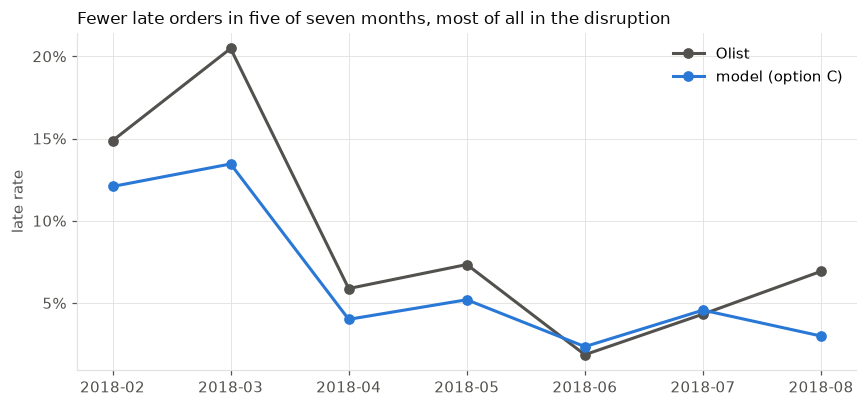

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(mt))
ax.plot(x, mt.olist_late, color=INK2, lw=2, marker="o", ms=6, label="Olist")
ax.plot(x, mt.model_late, color=BLUE, lw=2, marker="o", ms=6, label="model (option C)")
ax.set_xticks(x, mt.index)
ax.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("late rate")
ax.set_title("Fewer late orders in five of seven months, most of all in the disruption", loc="left", fontsize=11)
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "04_monthly_late.png", bbox_inches="tight")

The biggest gains come in the disruption (March: 20.5% → 13.5% late) and in August, when Olist cut its
promises to under 16 days and the model did not follow. In June and July, when everything was fast, the
model is marginally worse (+0.3–0.4 points) while promising about 1–5 days less.

## 6. What is a shorter promise worth?

This dataset cannot measure the upside of shorter promises: every order here was already placed, so we never
see the customers a long promise turned away. Published evidence fills the gap. In a field study at an online
retailer, Cui, Lu, Sun and Golden (2024, *Manufacturing & Service Operations Management*) changed only the
displayed promise. They found that **each day faster raised sales by about 0.73%**, but over-aggressive promises
increased returns and hurt retention, which is the same tension Phase 2 measured in reviews.

If that elasticity carried over to Olist (an assumption, not a measurement):

In [10]:
elasticity = 0.0073  # sales change per day of shorter promise (Cui et al., 2024)
b_days = per10k.loc["B. shorter promises, same late rate", "days shorter on average"]
print(f"Option B: promises {b_days:.1f} days shorter at the same late rate "
      f"-> indicative sales lift {b_days * elasticity:.1%} (if the published elasticity transfers)")

Option B: promises 2.1 days shorter at the same late rate -> indicative sales lift 1.6% (if the published elasticity transfers)


## 7. Recommendation

1. **Replace the network-wide promise with a per-order model promise at a fixed quantile.** Option C (chosen in
   January, run unchanged) would have cut Feb–Aug late deliveries from 9.0% to 6.5%. That is **about 28% fewer
   late orders and roughly 140 fewer 1-star reviews per 10,000 orders**, for promises only about half a day
   longer on average.
2. **Pick the point on the frontier deliberately.** Option A (same average promise, ~23% fewer late orders) and
   option B (same late rate, ~2 days shorter) are the two ends of what the model makes available. Which is better
   depends on the sales value of a shorter promise, which this data cannot measure.
3. **Test it before rolling it out.** The review gain rests on the Phase 2 dose-response holding under a new
   policy, and the sales gain on an elasticity from another retailer. Phase 5 designs the experiment that
   measures both, plus retention.
4. **Keep it simple.** The cost-aware optimiser adds nothing measurable over a single quantile.

In [11]:
front.to_csv(ROOT / "docs" / "phase4_frontier.csv", index=False)
opt.join(per10k).to_csv(ROOT / "docs" / "phase4_options.csv")